# Stallman-Verfahren zur Auswertung von Pumpversuchen mit hydraulischen Rändern

*Hydraulische Methoden | KIT*

**Ziel:** Den Einfluss positiver und negativer hydraulischer Ränder auf den Absenkungsverlauf verstehen und die Parameter **T**, **S** und **P** aus Pumpversuchsdaten bestimmen.

Wir betrachten zunächst die Theis-Lösung und das Spiegelbrunnenverfahren, erzeugen anschließend Typkurven und werten synthetische Daten sowie eine Übungsaufgabe aus. Benötigt werden **NumPy, SciPy und Matplotlib**. Die Berechnung der Typkurven orientiert sich an T. N. Olsthoorn ([Beispielcode](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html)).

## 1. Die Theis-Gleichung

Die Absenkung **s** im Abstand **r** vom mit konstanter Rate **Q** fördernden Brunnen nach Theis lautet:

$$
s(u)=\frac{Q}{4\pi T}W(u), \qquad u=\frac{r^2 S}{4Tt}.
$$

Dabei sind **T** die Transmissivität (m²/s), **S** der dimensionslose Speicherkoeffizient und **t** die Zeit seit Pumpbeginn (s). Die Brunnenfunktion ist

$$
W(u)=\int_u^\infty \frac{e^{-x}}{x}\,dx=E_1(u).
$$

## 2. Stallman: Grundwasserleiter mit hydraulischem Rand

Beim Spiegelbrunnenverfahren (*image-well method*) wird der reale Förderbrunnen durch einen fiktiven Brunnen ergänzt. Für eine **positive Randbedingung** (Nachlieferung, z. B. Fluss mit konstanter hydraulischer Höhe) wird die Wirkung eines Injektionsbrunnens abgezogen. Eine **negative Randbedingung** (undurchlässige Begrenzung) wird als zusätzlicher Förderbrunnen dargestellt.

$$
s(t)=\frac{Q}{4\pi T}\left[W(u_r)\mp W(u_i)\right],
$$

$$
u_r=\frac{r_r^2S}{4Tt},\qquad u_i=\frac{r_i^2S}{4Tt},\qquad P=\frac{r_i}{r_r}.
$$

Das Minuszeichen gilt für positive, das Pluszeichen für negative Randbedingungen. **rᵣ** und **rᵢ** sind die Abstände der Messstelle zum realen bzw. zum Spiegelbrunnen. Für **P → ∞** verschwindet der Einfluss des Randes und die Theis-Lösung wird erreicht. Das Modell setzt eine idealisierte geradlinigen Rand voraus.

**Modellannahmen:** homogener, isotroper, gespannter Grundwasserleiter mit konstanter Transmissivität; konstante Förderrate; idealisierter, geradliniger hydraulischer Rand. Das Modell berücksichtigt keine Brunnenverluste. **P** ist das Verhältnis der beiden Abstände und damit dimensionslos. Die hier ausgeführte Parameterschätzung behandelt eine **positive Randbedingung**.

### 2.1 Funktionen und Typkurven

Zunächst definieren wir die Brunnenfunktionen und erzeugen Typkurven für verschiedene Werte von **P**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import exp1
from scipy.optimize import least_squares

plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

def calc_ur(rr, S, T, t):
    """Dimensionless time parameter for the real well."""
    return rr**2 * S / (4 * T * np.asarray(t))

def calc_ri(rr, P):
    """Distance between observation well and image well: ri = P * rr."""
    return P * rr

def calc_ui(ri, S, T, t):
    """Dimensionless time parameter for the image well."""
    return ri**2 * S / (4 * T * np.asarray(t))

def W(u):
    """Theis well function W(u) = E1(u)."""
    return exp1(u)

def stallman_drawdown_pos(t, S, T, Q, rr, P):
    """Drawdown for positive (recharge) boundary."""
    ur = calc_ur(rr, S, T, t)
    ui = calc_ui(calc_ri(rr, P), S, T, t)
    return Q / (4 * np.pi * T) * (W(ur) - W(ui))

def stallman_drawdown_neg(t, S, T, Q, rr, P):
    """Drawdown for negative (no-flow) boundary."""
    ur = calc_ur(rr, S, T, t)
    ui = calc_ui(calc_ri(rr, P), S, T, t)
    return Q / (4 * np.pi * T) * (W(ur) + W(ui))

Ps = [1.1, 1.2, 1.4, 2, 4, 8, 16, 32, 64, 128]
ur_grid = np.logspace(-7, 1, 201)


Die Typkurven werden wie in der Übungsaufgabe doppellogarithmisch dargestellt. Für die positive Randbedingung kann die Differenz der Brunnenfunktionen bei kleinen **P** sehr klein werden.

Die folgende Abbildung zeigt zunächst die Typkurven für **positive und negative hydraulische Ränder gemeinsam**. Durchgezogene Linien kennzeichnen positive, gestrichelte Linien negative Randbedingungen. Danach werden beide Fälle für eine bessere Lesbarkeit getrennt dargestellt.

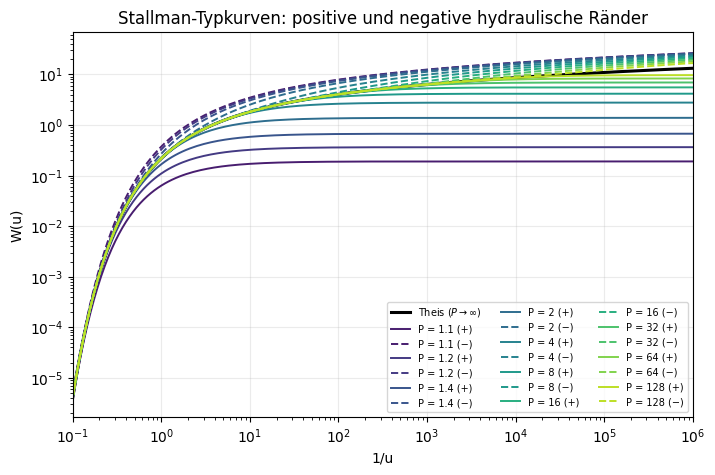

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(1 / ur_grid, W(ur_grid), color='black', linewidth=2.2,
        label=r'Theis ($P \to \infty$)')
colors = plt.cm.viridis(np.linspace(0.08, 0.9, len(Ps)))
for P, color in zip(Ps, colors):
    wi = W(ur_grid * P**2)
    ax.plot(1 / ur_grid, W(ur_grid) - wi, '-', color=color, linewidth=1.4,
            label=f'P = {P:g} (+)')
    ax.plot(1 / ur_grid, W(ur_grid) + wi, '--', color=color, linewidth=1.4,
            label=f'P = {P:g} (−)')
ax.set(xscale='log', yscale='log', xlim=(1e-1, 1e6),
       xlabel='1/u', ylabel='W(u)', title='Stallman-Typkurven: positive und negative hydraulische Ränder')
ax.legend(fontsize=7, ncol=3, loc='best')
plt.show()

**Getrennte Darstellung der positiven und negativen Ränder:**

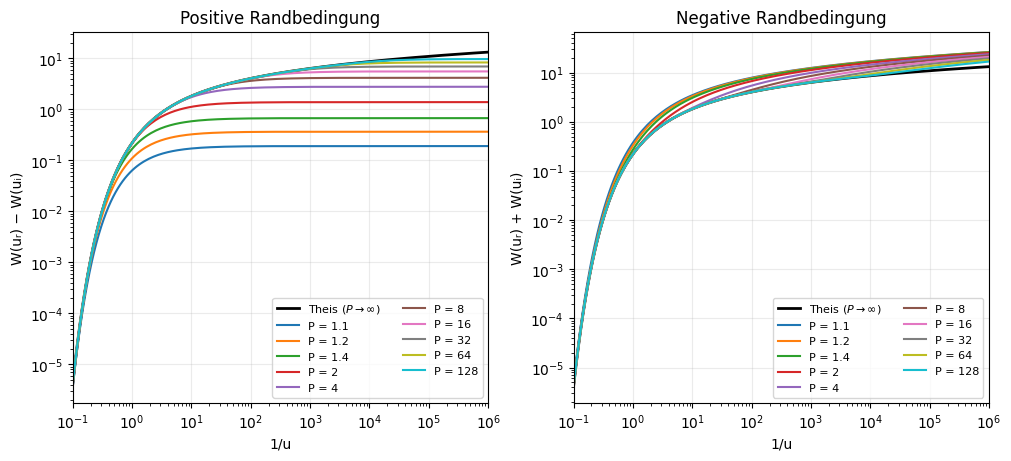

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
for ax, positive in zip(axs, (True, False)):
    ax.plot(1/ur_grid, W(ur_grid), 'k-', linewidth=2, label=r'Theis ($P \to \infty$)')
    for P in Ps:
        wi = W(ur_grid * P**2)
        response = W(ur_grid) - wi if positive else W(ur_grid) + wi
        ax.plot(1/ur_grid, response, label=f'P = {P:g}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xlabel('1/u'); ax.set_ylabel('W(uᵣ) − W(uᵢ)' if positive else 'W(uᵣ) + W(uᵢ)')
    ax.set_title(('Positive Randbedingung' if positive else 'Negative Randbedingung'))
    ax.legend(fontsize=8, ncol=2)
plt.show()

Bei negativen Rändern liegen die Typkurven relativ dicht beieinander; das erschwert eine rein grafische Bestimmung von **P**.

## 3. Synthetischer Pumpversuch

Wir erzeugen Messdaten für eine positive Randbedingung bei **P = 5**. Die Zeitreihe und Parameter entsprechen der Übung. Ein fester Zufalls-Seed macht das Messrauschen reproduzierbar.

**Ablauf:** Zuerst betrachten wir die Messwerte mit linearen Achsen. Danach vergleichen wir Messwerte und Modellkurve doppellogarithmisch.

In [4]:
Q = 0.01            # m³/s
r = 10.0            # m
S_true = 0.001      # dimensionless
T_true = 0.001      # m²/s
P_true = 5.0

t = np.array([150, 200, 300, 400, 600, 800, 1000, 1400, 1800,
              2400, 3200, 4800, 6000, 8000, 10000, 20000, 30000], dtype=float)

rng = np.random.default_rng(42)
s_clean = stallman_drawdown_pos(t, S_true, T_true, Q, r, P_true)
noise_sd = 2e-3
s = s_clean * (1 + noise_sd * rng.standard_normal(len(t)))
print(np.round(s, 5))

[1.09201 1.28035 1.55068 1.72667 1.93205 2.06218 2.15253 2.25499 2.31837
 2.37123 2.42381 2.46914 2.48436 2.50865 2.51687 2.53346 2.54755]


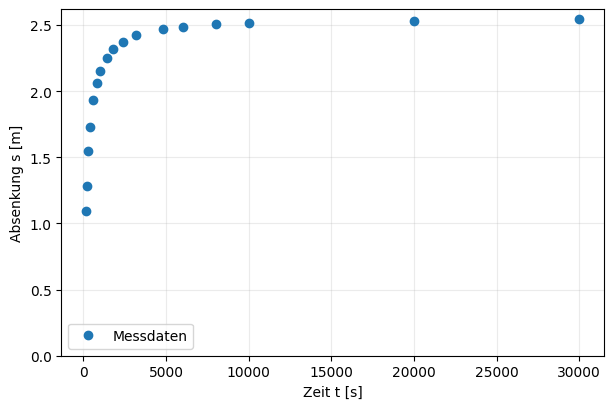

In [5]:
fig, ax = plt.subplots()
ax.plot(t, s, 'o', label='Messdaten')
ax.set_xlabel('Zeit t [s]')
ax.set_ylabel('Absenkung s [m]')
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

## 4. Nichtlineare Anpassung

Wie in der Übung bestimmen wir **S** und **T** durch Minimierung der quadratischen Abweichungen. Für numerische Stabilität optimieren wir logarithmierte Parameter, sodass **S** und **T** positiv bleiben. Die Anpassung verwendet die bekannte Förderrate **Q**, den Messstellenabstand **r** und zunächst ein vorgegebenes **P**.

**RMSE** bezeichnet die Wurzel des Mittelwerts der quadrierten Residuen (in m). Ein kleinerer RMSE bedeutet hier eine bessere Anpassung an die verwendeten Messwerte.

P=  5.0: S=1.0024e-03, T=9.9967e-04 m²/s, RMSE=0.00352 m


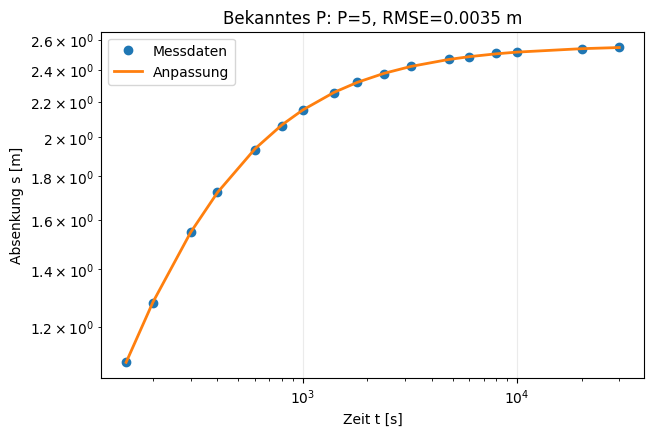

In [6]:
def fit_stallman(t, s, Q, r, P, guess=(1e-3, 1e-3)):
    """Fit positive-boundary Stallman curve; return S, T, RMSE, fitted curve."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    def residual(log_params):
        S, T = np.exp(log_params)
        return stallman_drawdown_pos(t, S, T, Q, r, P) - s
    result = least_squares(residual, np.log(guess), bounds=(np.log([1e-9, 1e-9]), np.log([1, 1])))
    Sfit, Tfit = np.exp(result.x)
    fit = stallman_drawdown_pos(t, Sfit, Tfit, Q, r, P)
    rmse = np.sqrt(np.mean((s - fit)**2))
    return Sfit, Tfit, rmse, fit

def search_P(P_values, t, s, Q, r, verbose=True):
    """Compare candidate P values by RMSE; return best-fit dictionary."""
    results = []
    for P in P_values:
        Sfit, Tfit, rmse, fit = fit_stallman(t, s, Q, r, float(P))
        results.append(dict(P=float(P), S=Sfit, T=Tfit, rmse=rmse, fit=fit))
        if verbose:
            print(f'P={P:5.1f}: S={Sfit:.4e}, T={Tfit:.4e} m²/s, RMSE={rmse:.5f} m')
    return min(results, key=lambda result: result['rmse'])

def plot_fit(t, s, result, heading):
    fig, ax = plt.subplots()
    ax.plot(t, s, 'o', label='Messdaten')
    ax.plot(t, result['fit'], '-', label='Anpassung', linewidth=2)
    ax.set_xlabel('Zeit t [s]')
    ax.set_ylabel('Absenkung s [m]')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"{heading}: P={result['P']:g}, RMSE={result['rmse']:.4f} m")
    ax.legend()
    plt.show()

best_known = search_P([5], t, s, Q, r)
plot_fit(t, s, best_known, 'Bekanntes P')

Die geschätzten Werte sollten nahe an den zur Erzeugung verwendeten Parametern liegen.

### 4.1 Suche nach P bei unbekannter Lage des Randes

Ist **P** nicht bekannt, passen wir für verschiedene Kandidaten **S** und **T** an und wählen den kleinsten RMSE. Zuerst verwenden wir ein grobes Raster.

P=  1.1: S=3.0628e-04, T=6.0150e-05 m²/s, RMSE=0.04127 m
P=  1.2: S=5.3641e-04, T=1.1504e-04 m²/s, RMSE=0.04086 m
P=  1.4: S=8.4509e-04, T=2.1219e-04 m²/s, RMSE=0.03953 m
P=  2.0: S=1.1964e-03, T=4.3603e-04 m²/s, RMSE=0.03349 m
P=  4.0: S=1.1148e-03, T=8.6425e-04 m²/s, RMSE=0.01124 m
P=  8.0: S=7.4419e-04, T=1.2809e-03 m²/s, RMSE=0.02221 m
P= 16.0: S=4.2228e-04, T=1.6864e-03 m²/s, RMSE=0.05798 m
P= 32.0: S=2.1703e-04, T=2.0817e-03 m²/s, RMSE=0.09209 m
P= 64.0: S=1.0553e-04, T=2.4648e-03 m²/s, RMSE=0.12232 m
P=128.0: S=5.0737e-05, T=2.8279e-03 m²/s, RMSE=0.14826 m
Bester Wert: P=4


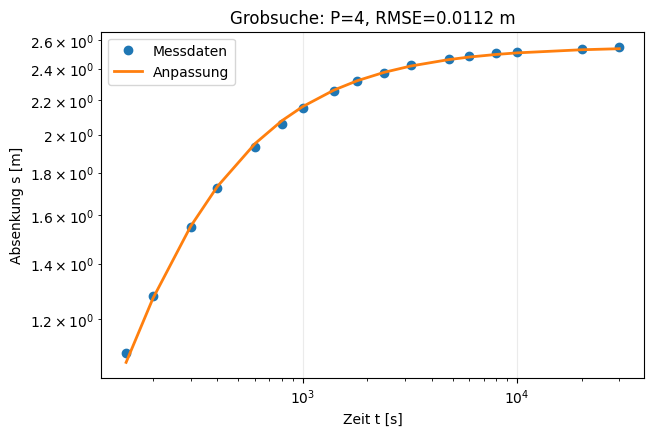

In [7]:
P_coarse = np.array([1.1, 1.2, 1.4, 2, 4, 8, 16, 32, 64, 128])
best_coarse = search_P(P_coarse, t, s, Q, r)
print(f"Bester Wert: P={best_coarse['P']:g}")
plot_fit(t, s, best_coarse, 'Grobsuche')

Nun verfeinern wir das Suchraster im Bereich **P = 4 bis 8**.

P=  4.0: S=1.1148e-03, T=8.6425e-04 m²/s, RMSE=0.01124 m
P=  5.0: S=1.0024e-03, T=9.9967e-04 m²/s, RMSE=0.00352 m
P=  6.0: S=9.0241e-04, T=1.1094e-03 m²/s, RMSE=0.00832 m
P=  7.0: S=8.1690e-04, T=1.2015e-03 m²/s, RMSE=0.01557 m
P=  8.0: S=7.4419e-04, T=1.2809e-03 m²/s, RMSE=0.02221 m
Bester Wert: P=5


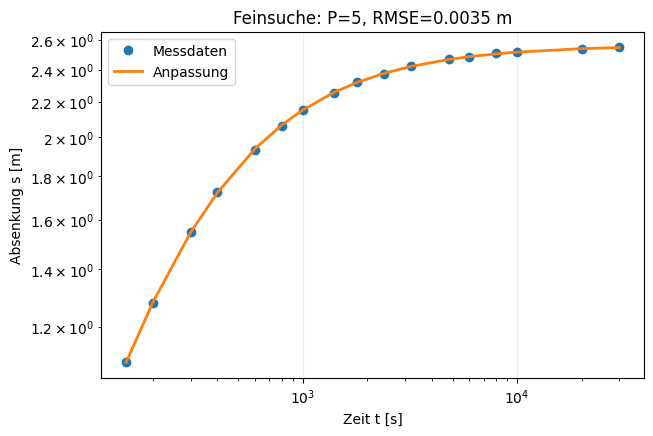

In [8]:
P_fine = np.array([4, 5, 6, 7, 8])
best_fine = search_P(P_fine, t, s, Q, r)
print(f"Bester Wert: P={best_fine['P']:g}")
plot_fit(t, s, best_fine, 'Feinsuche')

Der beste Wert liegt bei **P = 5**, dem für das synthetische Beispiel vorgegebenen Wert.

## 5. Übungsaufgabe mit gemessenen Pumpversuchsdaten

Für die Übungsaufgabe gelten **Q = 6 L/s** und **r = 40 m**. Wir übernehmen die Messdaten unverändert und suchen wie oben erst grob, dann feiner nach **P**.

Auch hier betrachten wir zunächst die Messdaten auf linearen Achsen. Die anschließenden Kurvenanpassungen werden doppellogarithmisch dargestellt.

In [9]:
Q_ex = 0.006     # m³/s
r_ex = 40.0      # m
t_ex = np.array([10, 18, 32, 56, 100, 178, 316, 562, 1000, 1778,
                 3162, 5623, 10000, 17780, 31620, 56230, 100000, 200000], dtype=float)
s_ex = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31, 0.4,
                 0.49, 0.58, 0.67, 0.75, 0.82, 0.87, 0.9, 0.92, 0.93, 0.93])

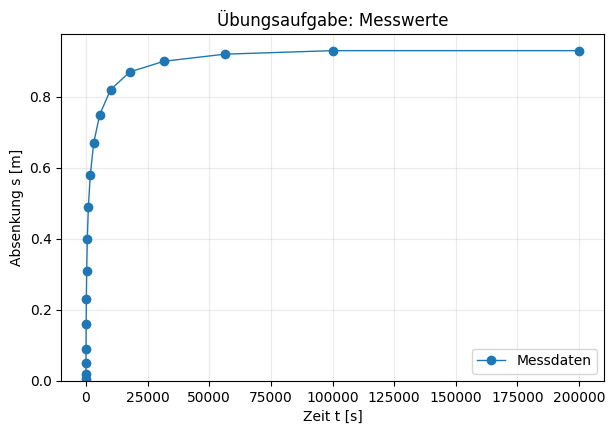

In [10]:
fig, ax = plt.subplots()
ax.plot(t_ex, s_ex, 'o-', linewidth=1, label='Messdaten')
ax.set(xlabel='Zeit t [s]', ylabel='Absenkung s [m]', title='Übungsaufgabe: Messwerte')
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

### 5.1 Grobe Suche

P=  1.1: S=9.4301e-05, T=1.0543e-04 m²/s, RMSE=0.07568 m
P=  1.2: S=1.6545e-04, T=2.0161e-04 m²/s, RMSE=0.07537 m
P=  1.4: S=2.6218e-04, T=3.7164e-04 m²/s, RMSE=0.07433 m
P=  2.0: S=3.8116e-04, T=7.6174e-04 m²/s, RMSE=0.06970 m
P=  4.0: S=3.9285e-04, T=1.4965e-03 m²/s, RMSE=0.05350 m
P=  8.0: S=3.0920e-04, T=2.1885e-03 m²/s, RMSE=0.03126 m
P= 16.0: S=2.2147e-04, T=2.8282e-03 m²/s, RMSE=0.00683 m
P= 32.0: S=1.5526e-04, T=3.4004e-03 m²/s, RMSE=0.01892 m
P= 64.0: S=1.1460e-04, T=3.8630e-03 m²/s, RMSE=0.04111 m
P=128.0: S=1.0195e-04, T=4.1009e-03 m²/s, RMSE=0.05697 m
Bester Wert: P=16


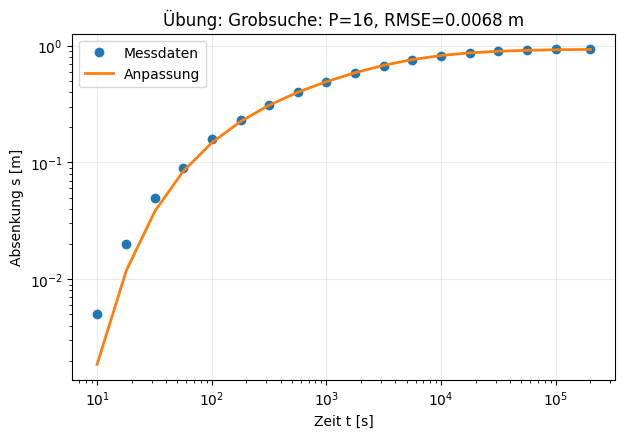

In [11]:
best_ex_coarse = search_P(P_coarse, t_ex, s_ex, Q_ex, r_ex)
print(f"Bester Wert: P={best_ex_coarse['P']:g}")
plot_fit(t_ex, s_ex, best_ex_coarse, 'Übung: Grobsuche')

### 5.2 Feinere Suche

Wir verfeinern das Suchraster für **P** nun weiter und vergleichen Kandidaten zwischen 14 und 32.

Beste Anpassung: P=19, S=2.0272e-04, T=2.9773e-03 m²/s, RMSE=0.00287 m


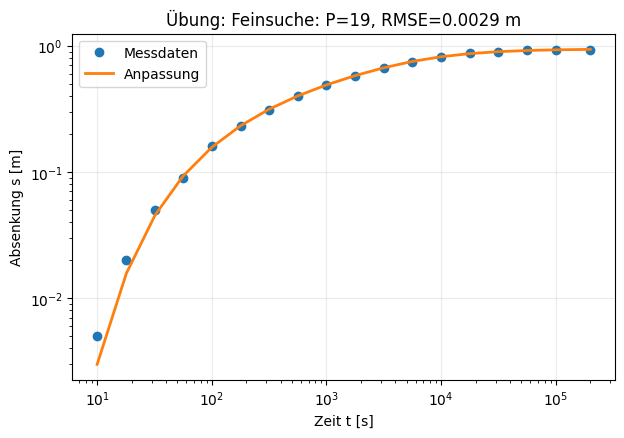

In [12]:
P_ex_fine = np.arange(14, 33)
best_ex = search_P(P_ex_fine, t_ex, s_ex, Q_ex, r_ex, verbose=False)
print(f"Beste Anpassung: P={best_ex['P']:.0f}, S={best_ex['S']:.4e}, "
      f"T={best_ex['T']:.4e} m²/s, RMSE={best_ex['rmse']:.5f} m")
plot_fit(t_ex, s_ex, best_ex, 'Übung: Feinsuche')

Die beiden Suchraster illustrieren, wie die Position des Randes über **P** abgeschätzt werden kann. Die Ergebnisse hängen von der Modellannahme eines idealisierten hydraulischen Randes ab. Eine noch engere Suche kann die numerische Anpassung verbessern, muss aber nicht zu einer belastbareren hydrogeologischen Interpretation führen.

## 6. Ergebnisse und Einordnung

Die **Grobsuche** grenzt den möglichen Bereich von **P** ein; die **Feinsuche** liefert innerhalb des gewählten Rasters die kleinste mittlere quadratische Abweichung. Für die Übungsaufgabe ergeben sich:

| Parameter | Ergebnis | Bedeutung |
|---|---:|---|
| **P** | 19 | Abstand zum Spiegelbrunnen relativ zum Messstellenabstand |
| **T** | ca. 2,98 · 10⁻³ m²/s | Transmissivität |
| **S** | ca. 2,03 · 10⁻⁴ | dimensionsloser Speicherkoeffizient |
| **RMSE** | ca. 0,0029 m | mittlerer Anpassungsfehler |

**Interpretation:** Die Ergebnisse beziehen sich auf das idealisierte Modell eines positiven hydraulischen Randes. Eine kleine Anpassungsabweichung allein beweist weder die genaue Lage des Randes noch die Eindeutigkeit der Parameter. Die Art und Lage des hydraulischen Randes sollten zusätzlich hydrogeologisch plausibilisiert werden.

## Literatur

- Theis, C. V. (1935): The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage. *Transactions, American Geophysical Union*, 16, 519–524.
- Stallman, R. W. (1965): Effects of water-table conditions on water-level changes near pumping wells. *Water Resources Research*, 1, 295–312.
- Olsthoorn, T. N.: [Transient Groundwater Flow – examples](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html) (Codebezug).